In [ ]:
%load_ext autoreload
%autoreload 2

In [ ]:
import os
import torch.backends.cudnn as cudnn
import torch
import torchvision
import torch.nn.functional as F
import numpy as np
import pandas as pd
import time
from datetime import datetime 
import pdb
import yaml
import sys
import glob
import shutil
import tqdm
import matplotlib.pyplot as plt
from PIL import Image
import cv2

#from pytorch_grad_cam import GradCAM
#from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
#from pytorch_grad_cam.utils.image import show_cam_on_image
import captum
from captum.attr import IntegratedGradients, Occlusion, LayerGradCam, LayerAttribution, GuidedGradCam
from matplotlib.colors import LinearSegmentedColormap
from captum.attr import visualization as viz



sys.path.append('../../MARS')
sys.path.append('../../MARS/run_lars/code_3d')


#from MARS.run_lars.code_3d.dataset import get_datasets, dataset_center
from MARS.run_lars.code_3d.utils import model_prediction, my_model



KeyboardInterrupt: 

In [63]:
from MARS.run_lars.code_3d.dataset import dataset_3d, dataset_3d_center, get_datasets_3d

In [ ]:
xd = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/results/run_lars_on_mars_3D/pred_0.csv').iloc[:,:62]

In [67]:
data_path_img='/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/images_h5'
data_path='/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/train_df.csv'

In [64]:
zz = get_datasets_3d(dataset_type = 'val', transform=None, norm=False, 
                     data_path_img=data_path_img, 
                     data_path=data_path, target_label_name='PET_jco')


In [68]:
zz.df

,filepath,filename,filename_header,fullfile,patient_age,patient_sex,patient_weight,smoking_status,accession,study_uid,...,frame_duration,tracer,tracer_injection_time,tracer_dose,tracer_halflife,image_filter,contrast_route,axial_fov,PET_jco,PET_imwg
0,35942981,35942981_pt_0.h5,35942981_pt_0.pkl,35942981/35942981_pt_0.h5,064Y,M,104.326258,UNKNOWN,35942981,1.2.840.114350.2.232.2.798268.2.743570754.1,...,120000.0,Fluorodeoxyglucose,164400.0,6.031000e+08,6586.2,NaN,NaN,1857.0,0.0,0.0
1,23011715,23011715_pt_2.h5,23011715_pt_2.pkl,23011715/23011715_pt_2.h5,046Y,F,71.668000,UNKNOWN,23011715,1.2.840.114350.2.232.2.798268.2.516194816.1,...,54054.0,Fluorodeoxyglucose,82000.0,4.921000e+08,6586.2,NaN,NaN,1650.0,0.0,0.0
2,5479860,5479860_pt_0.h5,5479860_pt_0.pkl,5479860/5479860_pt_0.h5,064Y,M,59.928000,NO,5479860,1.2.840.113696.323972.500.1494703.20101011164651,...,180000.0,NaN,193000.0,5.542600e+08,6586.2,NaN,NaN,975.0,1.0,1.0
3,41177892,41177892_pt_0.h5,41177892_pt_0.pkl,41177892/41177892_pt_0.h5,065Y,M,65.772000,UNKNOWN,41177892,1.2.840.114350.2.232.2.798268.2.839131001.1,...,60022.0,Fluorodeoxyglucose,124000.0,5.753500e+08,6586.2,NaN,NaN,1768.0,1.0,1.0
4,16563246,16563246_pt_0.h5,16563246_pt_0.pkl,16563246/16563246_pt_0.h5,070Y,M,84.368192,UNKNOWN,16563246,1.2.840.114350.2.232.2.798268.2.276427106.1,...,90000.0,Fluorodeoxyglucose,100600.0,5.812700e+08,6586.2,NaN,NaN,1983.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
745,16657873,16657873_pt_0.h5,16657873_pt_0.pkl,16657873/16657873_pt_0.h5,081Y,F,70.760419,UNKNOWN,16657873,1.2.840.114350.2.232.2.798268.2.287939082.1,...,120000.0,Fluorodeoxyglucose,103200.0,5.246600e+08,6586.2,NaN,NaN,852.0,1.0,1.0
746,11771804,11771804_pt_0.h5,11771804_pt_0.pkl,11771804/11771804_pt_0.h5,081Y,F,61.688570,UNKNOWN,11771804,1.2.840.114350.2.232.2.798268.2.124897776.1,...,120000.0,Fluorodeoxyglucose,95000.0,5.616600e+08,6586.2,NaN,NaN,1734.0,0.0,0.0
747,11420062,11420062_pt_0.h5,11420062_pt_0.pkl,11420062/11420062_pt_0.h5,060Y,M,77.110713,UNKNOWN,11420062,1.2.840.114350.2.232.2.798268.2.125217819.1,...,120000.0,Fluorodeoxyglucose,132200.0,5.823800e+08,6586.2,NaN,NaN,1860.0,1.0,1.0
748,31463818,31463818_pt_0.h5,31463818_pt_0.pkl,31463818/31463818_pt_0.h5,068Y,M,74.390000,UNKNOWN,31463818,1.2.840.114350.2.232.2.798268.2.669604641.1,...,54053.0,Fluorodeoxyglucose,112000.0,4.958000e+08,6586.2,NaN,NaN,1795.0,0.0,0.0


In [70]:
import h5py

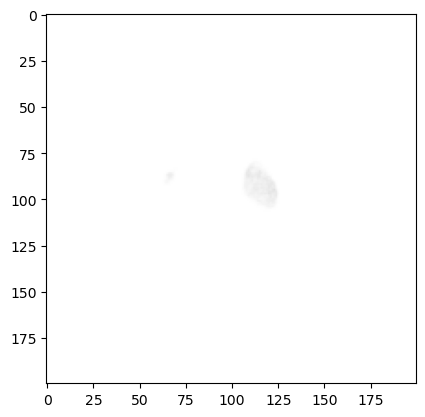

In [93]:
f = h5py.File('/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/images_h5/35942981/35942981_pt_0.h5', "r")
zd = np.array(f['image'])

#zd = np.transpose(zd, (2,1,0))
#zd = np.flip(zd, axis=0)
plt.imshow(zd[:,:,20], cmap='gray_r', vmin=0, vmax=10)

In [59]:
# find mean value of the images across all images in the dataset
listo = []
num=100
for i in range(num):
    print(i)
    yu = zz[i][0]
    yu = torch.clip(yu, 0, 30)
    listo.append(yu)

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99


In [60]:
stacked = torch.stack(listo)

print(stacked.mean())
print(stacked.std())

tensor(0.0906)
tensor(0.4783)


In [42]:
for i in range(40):
    yu = zz[i][0]
    if i == 4:
        break
    print(yu.shape)

ps: [4.07284 4.07284 3.     ]
(170, 192, 567)
ps: [4.07283 4.07283 5.     ]
(95, 171, 493)
ps: [4.06270479 4.06270479 5.        ]
(197, 197, 297)
ps: [1.65 1.65 4.  ]
(111, 189, 540)
ps: [4.07283 4.07283 3.     ]


In [16]:
# I/O PARAMS
# INPUT
data_path_img= '/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/images_h5/' # path to directory housing h5 files
data_path_datafiles= '/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/train_df.csv' # path to directory housing datafiles (csv files)
#model_path_pattern: "/gpfs/data/mayerhoeferlab/projects/lars/lars-avg-max_chpt/LARS_trained_state-dict_*.pth"
model_path_pattern= "/gpfs/data/mayerhoeferlab/projects/lars/lars3d_chpt/LARS_trained_state-dict_0.pth"


# OUTPUT
output= "/gpfs/data/mayerhoeferlab/projects/myeloma/results/run_lars_on_mars_3D"


# DATA PARAMS
normalize = True
dataset_type = 'val'

# DATALOADER PARAMS
batch_size = 1
workers = 6

In [ ]:
model = model_prediction(model_path_pattern)
model.cuda()

RuntimeError: Error(s) in loading state_dict for my_model:
	Missing key(s) in state_dict: "features.0.weight", "features.1.weight", "features.1.bias", "features.1.running_mean", "features.1.running_var", "features.4.0.conv1.weight", "features.4.0.bn1.weight", "features.4.0.bn1.bias", "features.4.0.bn1.running_mean", "features.4.0.bn1.running_var", "features.4.0.conv2.weight", "features.4.0.bn2.weight", "features.4.0.bn2.bias", "features.4.0.bn2.running_mean", "features.4.0.bn2.running_var", "features.4.1.conv1.weight", "features.4.1.bn1.weight", "features.4.1.bn1.bias", "features.4.1.bn1.running_mean", "features.4.1.bn1.running_var", "features.4.1.conv2.weight", "features.4.1.bn2.weight", "features.4.1.bn2.bias", "features.4.1.bn2.running_mean", "features.4.1.bn2.running_var", "features.4.2.conv1.weight", "features.4.2.bn1.weight", "features.4.2.bn1.bias", "features.4.2.bn1.running_mean", "features.4.2.bn1.running_var", "features.4.2.conv2.weight", "features.4.2.bn2.weight", "features.